Pairs Trading


Loosely based on Gatev, Goetzmann, and Rouwenhorst(2006), Pairs Trading: Performance of a Relative-Value Arbitrage Rule

http://www-stat.wharton.upenn.edu/~steele/Courses/434/434Context/PairsTrading/PairsTradingGGR.pdf

By Hong Kee Sul

Step 1. Import Modules

In [13]:
!pip install yfinance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import yfinance as yf
import statistics

from datetime import datetime
from dateutil.relativedelta import relativedelta

plt.style.use('fivethirtyeight')


Step 2. Set GICS sector, and Start Date

In [14]:

mySector = 'Consumer Staples'

sDate = '2024-01-01'
eDate =  (datetime.strptime(sDate, '%Y-%m-%d') + relativedelta(months=12)).strftime( '%Y-%m-%d')

print(sDate)
print(eDate)

2024-01-01
2025-01-01


Step 3. Generate List of S&P500 Firms


- Lists of S&P500 from wikipedia
  - https://en.wikipedia.org/wiki/List_of_S%26P_500_companies

- Load List of Tickers from the selected GICS sector

- Remove 5 Duplicate Tickers (5 extra from 505 tickers in S&P500)

In [15]:
url = 'https://raw.githubusercontent.com/datasets/s-and-p-500-companies/master/data/constituents.csv'
import pandas as pd
gics = pd.io.parsers.read_csv(url)

In [16]:
#payload=pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
#gics = payload[0]
gics2 = gics[gics['GICS Sector']==mySector]
myTickerList = list(gics2['Symbol'].values)

print(len(myTickerList), myTickerList)

#removeTickerList = ['GOOGL', 'DISCA', 'NWSA', 'FOXA', 'UAA']
removeTickerList = ['KVUE']
# KVUE: Baru IPO pada 4 Mei 2023, tidak punya harga saham sepanjang 2022.


for ticker in removeTickerList:
  try:
    myTickerList.remove(ticker)
  except:
    pass

print(len(myTickerList), myTickerList)


34 ['MO', 'ADM', 'BF.B', 'BG', 'CASY', 'CHD', 'CLX', 'KO', 'CL', 'STZ', 'COST', 'DG', 'DLTR', 'EL', 'GIS', 'HSY', 'HRL', 'KVUE', 'KDP', 'KMB', 'KHC', 'KR', 'MKC', 'MDLZ', 'MNST', 'PEP', 'PM', 'PG', 'SJM', 'SYY', 'TGT', 'TSN', 'VYLR', 'WMT']
33 ['MO', 'ADM', 'BF.B', 'BG', 'CASY', 'CHD', 'CLX', 'KO', 'CL', 'STZ', 'COST', 'DG', 'DLTR', 'EL', 'GIS', 'HSY', 'HRL', 'KDP', 'KMB', 'KHC', 'KR', 'MKC', 'MDLZ', 'MNST', 'PEP', 'PM', 'PG', 'SJM', 'SYY', 'TGT', 'TSN', 'VYLR', 'WMT']


Step 4. Generating Cumulative Returns

- Load 1 year of Adj. Close Stock Price Data from Yahoo Finance

- Create Cumulative Return from the Adj. Close Price

In [17]:
import yfinance as yf
import pandas as pd

# 1. Download data
# auto_adjust=False forces yfinance to return 'Adj Close' (fixing the FutureWarning)
# threads=True speeds up the download for many tickers
data = yf.download(myTickerList, start=sDate, end=eDate, group_by='column', auto_adjust=False, threads=True)

# 2. Select 'Adj Close' safely
if 'Adj Close' in data.columns:
    data = data['Adj Close']
else:
    # Fallback if only one level exists or 'Adj Close' is missing
    print("Warning: 'Adj Close' not found. Using 'Close' or checking data format.")
    # Attempt to use 'Close' if Adj Close is missing (common with auto_adjust=True)
    if 'Close' in data.columns:
        data = data['Close']

# 3. Clean Data
# Drop rows where ALL tickers are missing (e.g., holidays)
data = data.dropna(how='all')
# Drop columns (tickers) that have NO data at all (like 'FOX' in your error)
data = data.dropna(axis='columns', how='all')

# 4. Calculate Cumulative Returns
if not data.empty:
    # Vectorized calculation (faster than loop)
    data_CumRet = data / data.iloc[0]
    print(data_CumRet.head())
    print(data_CumRet.tail())
else:
    print("Error: DataFrame is empty. Check your dates or ticker symbols.")

[*************         27%                       ]  9 of 33 completedERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BF.B"}}}
[*********************100%***********************]  33 of 33 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1704085200, endDate = 1735707600")')
ERROR:yfinance:['BF.B']: YFTzMissingError('possibly delisted; no timezone found')


Ticker           ADM        BG      CASY       CHD        CL       CLX  \
Date                                                                     
2024-01-02  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000   
2024-01-03  1.005085  0.987882  0.994884  0.993444  0.989718  0.978091   
2024-01-04  0.986119  0.974877  1.004755  0.999471  0.995292  0.984518   
2024-01-05  0.973199  0.965714  1.024353  0.992598  0.990833  0.976501   
2024-01-08  0.976636  0.976946  1.028857  0.997885  0.996036  0.982998   

Ticker          COST        DG      DLTR        EL  ...        MO       PEP  \
Date                                                ...                       
2024-01-02  1.000000  1.000000  1.000000  1.000000  ...  1.000000  1.000000   
2024-01-03  0.990840  0.934843  0.959169  0.953317  ...  0.995671  1.000231   
2024-01-04  0.996465  0.959624  0.955381  0.953730  ...  0.998557  0.991672   
2024-01-05  1.008238  0.966745  0.956153  0.943967  ...  0.997835  0.977040   
2024-01

Step 5. Define the find_pairs function

- From 21 stocks, the number of possible pairs is
  - 21 C 2 = 20*21/2 = 210

- Role of the find_pairs function:

    - For all possible pair of Stocks,

    - Calculate the sum of squared spread(error) between the stock cumulative returns for each pair




In [18]:
MAX_SSE = 0.8

def calcSse(data1, data2):
  if len(data1)!= len(data2):
    print('err in rmse data length')
    return None
  else:
    sum = 0
    for i, d1 in enumerate(data1):
      sum += (d1-data2[i])**2
    return sum

def find_pairs(data):
    n = data.shape[1]
    score_matrix = np.zeros((n, n))
    keys = data.keys()
    pairs = []
    for i in range(n):
        score_matrix[i, i] = MAX_SSE
        for j in range(i+1, n):
            S1 = data[keys[i]]
            S2 = data[keys[j]]
            sum = calcSse(S1, S2)
            pairs.append([keys[i], keys[j], sum])
            score_matrix[i, j] = sum
            score_matrix[j, i] = MAX_SSE
    return (score_matrix, pairs)



Step 6. Execute find_pairs function, and show the heatmap of the results

- Show a heatmap of the SSE(Sum of Squared Errors), excluding the one that have SSE over MAX_SSE(2).

/tmp/ipykernel_538/946648378.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sum += (d1-data2[i])**2


<Axes: >

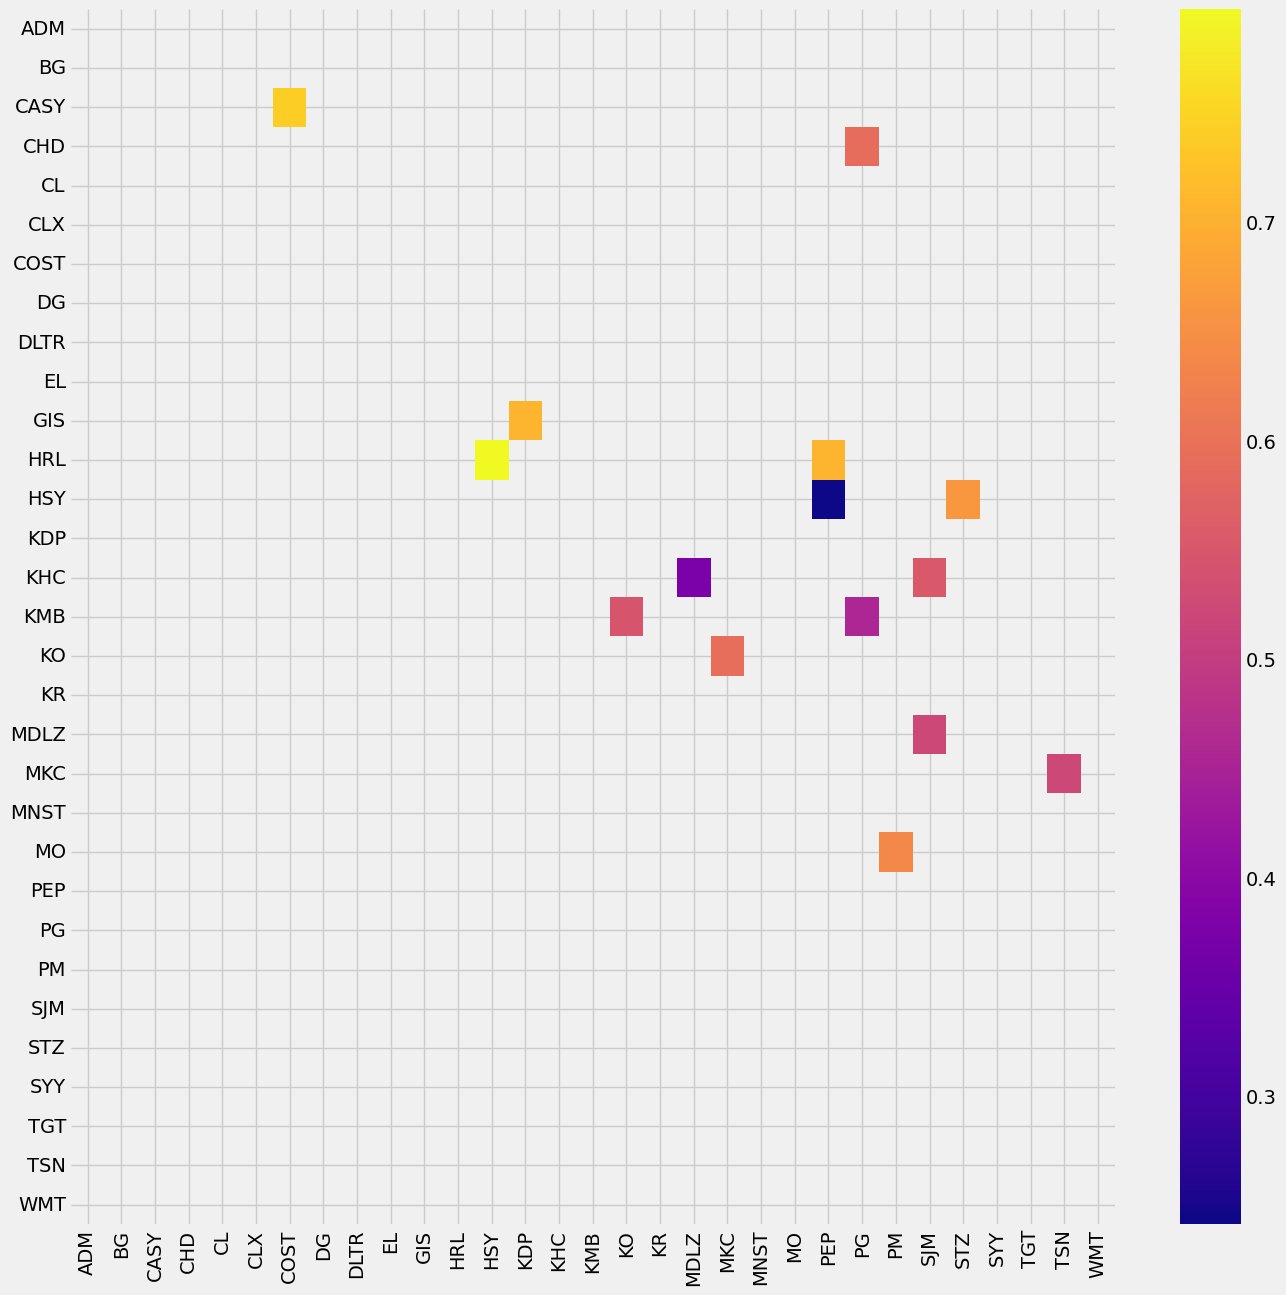

In [19]:
scoreData, pairsData = find_pairs(data_CumRet)

fig, ax = plt.subplots(figsize=(15,15))
seaborn.heatmap(scoreData, xticklabels = data_CumRet.columns, yticklabels = data_CumRet.columns, cmap = 'plasma', mask = ( (scoreData >= MAX_SSE)), ax=ax)



Step 7. Print Results
- Show the combination(pair) of stocks that have a SSE lower than MAX_SSE, ordered by SSE

In [20]:
pairsData.sort(key=lambda x: float(x[2]))
for pData in pairsData:
  if pData[2]<MAX_SSE:
    print ('\t'.join([str(a) for a in pData]))

HSY	PEP	0.24140512792132282
KHC	MDLZ	0.37549145637424486
KMB	PG	0.4546892931824146
MKC	TSN	0.522055255991054
MDLZ	SJM	0.5229501832671908
KMB	KO	0.5455357096098308
KHC	SJM	0.5528092765822665
CHD	PG	0.5903517862634264
KO	MKC	0.5910534747639523
MO	PM	0.6384376035842255
HSY	STZ	0.6622011382443282
HRL	PEP	0.7044912798429643
GIS	KDP	0.7056497190498846
CASY	COST	0.7398158555215093
HRL	HSY	0.7972576965300304


Step 8. Choosing Pairs

- Now we must choose the pairs wisely. I advise you to make qualitative choices of which companies may not have related businesses or not.

- Here, I decide to remove 'DIS'-'TMUS', 'CHTR'-'CMCSA', 'DIS'-'VZ', 'GOOG'-'TTWO', 'CMCSA'-'T', 'NWS'-'T', 'OMC'-'TMUS' pair, due to the fact that they might not have related business.

- Likewise, I did not choose 'CMCSA'-'T' and 'OMC'-'VZ' pair since we already choose the 'CHTR'-'T' and the 'TMUS'-'VZ' pair.

In [30]:
# Let's choose from the following 15 candidate pairs (ranked by SSE)
"""
HSY   PEP   0.24140512792132282
KHC   MDLZ  0.37549145637424486
KMB   PG    0.4546892931824146
MKC   TSN   0.522055255991054
MDLZ  SJM   0.5229501832671908
KMB   KO    0.5455357096098308
KHC   SJM   0.5528092765822665
CHD   PG    0.5903517862634264
KO    MKC   0.5910534747639523
MO    PM    0.6384376035842255
HSY   STZ   0.6622011382443282
HRL   PEP   0.7044912798429643
GIS   KDP   0.7056497190498846
CASY  COST  0.7398158555215093
HRL   HSY   0.7972576965300304
"""

# Selected 5 pairs (low SSE, related businesses, and no overlapping stocks)
selectedPairs = [
    ('HSY', 'PEP'),    # Both operate in packaged snacks; lowest SSE among all candidates.
    ('KHC', 'MDLZ'),   # Both produce packaged foods and share historical corporate origins.
    ('KMB', 'PG'),     # Direct competitors in diapers, feminine care, and tissue products.
    ('MO', 'PM'),      # Both operate in tobacco and share the Marlboro brand heritage.
    ('CASY', 'COST')   # Both operate consumer retail businesses selling groceries and fuel.
]

Step 9. Compare Adj. Close prices

- Now let's visualize the data - Adj. Close Price Comparison, for the first pair ('TMUS'-'VZ')

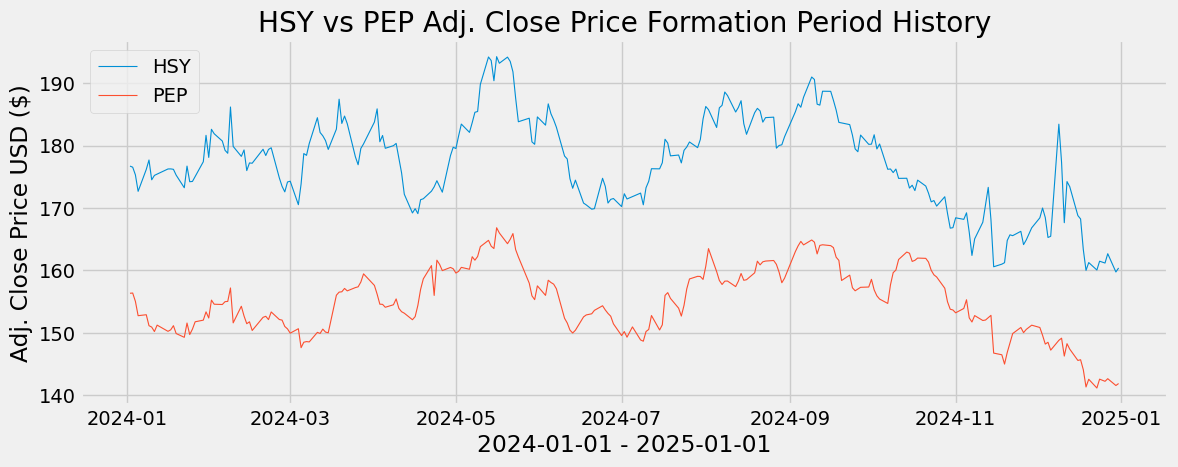

In [26]:
ticker1 = 'HSY'
ticker2 = 'PEP'

plt.figure(figsize=(12.5, 4.5))
plt.plot(data[ticker1], label = ticker1, linewidth = 0.8)
plt.plot(data[ticker2], label = ticker2, linewidth = 0.8)
plt.title(ticker1+ ' vs ' + ticker2 + ' Adj. Close Price Formation Period History')
plt.xlabel(sDate+" - "+eDate)
plt.ylabel('Adj. Close Price USD ($)')
plt.legend(loc='upper left')
plt.show()

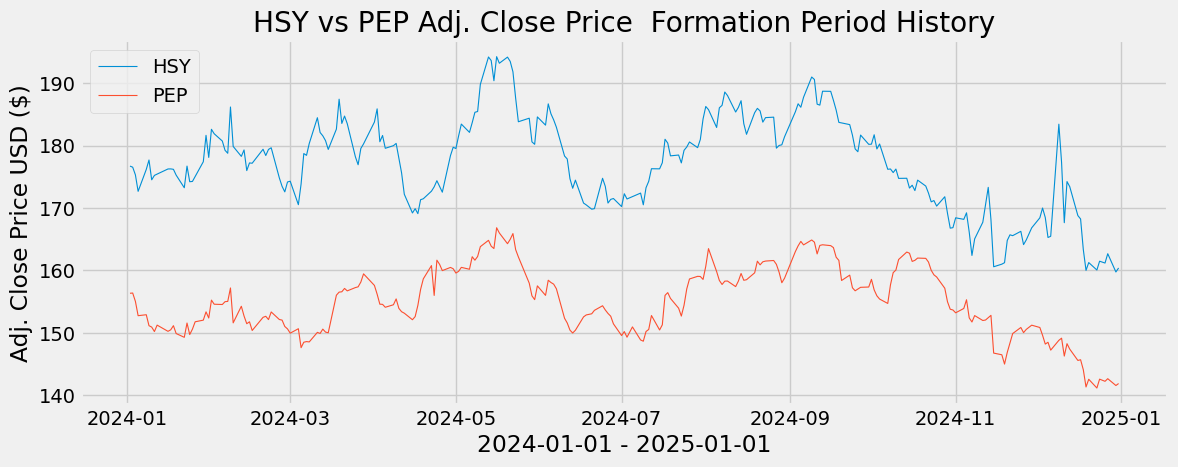

In [27]:
plt.figure(figsize=(12.5, 4.5))
plt.plot(data[ticker1], label = ticker1, linewidth = 0.8)
plt.plot(data[ticker2], label = ticker2, linewidth = 0.8)
plt.title(ticker1+ ' vs ' + ticker2 + ' Adj. Close Price  Formation Period History')
plt.xlabel(sDate+" - "+eDate)
plt.ylabel('Adj. Close Price USD ($)')
plt.legend(loc='upper left')
plt.show()

Step 10. Compare Cumulative Returns

- Now let's visualize the data - Cum Return Comparison, for the first pair ('TMUS'-'VZ')

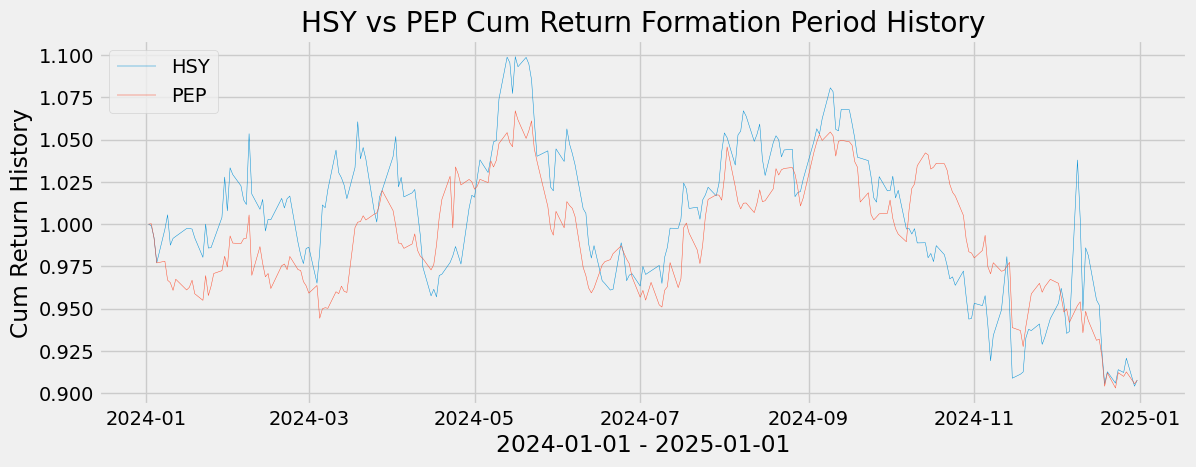

In [28]:


plt.figure(figsize=(12.5, 4.5))
plt.plot(data_CumRet[ticker1], label = ticker1, linewidth = 0.35)
plt.plot(data_CumRet[ticker2], label = ticker2, linewidth = 0.35)
plt.title(ticker1+ ' vs ' + ticker2 + ' Cum Return Formation Period History')
plt.xlabel(sDate+" - "+eDate)
plt.ylabel('Cum Return History')
plt.legend(loc='upper left')
plt.show()


We see that this pair's stock returns has been very hightly correlated for the 1 year period.

Step 11. Calculate the STDEV of the stock return spread.
- A quantitative measure of how similar the stocks are


In [29]:

stdev = statistics.stdev(data_CumRet[ticker1]-data_CumRet[ticker2])
print('Stdev of spread in the Formation Period is: ', stdev)

Stdev of spread in the Formation Period is:  0.028849697253263897
